<a href="https://colab.research.google.com/github/mikechechelnitsky-cpu/APStatsDS27/blob/main/GameDemo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You are playing a game called Race to 20 against one opponent.

Both players begin at position 1 and take turns advancing along a board. The first player to reach or pass position 20 wins.

On each turn, you must roll a standard six-sided die. Before rolling, however, you may choose to take an additional risk by flipping a fair coin.

You have two possible strategies:

Strategy A — Safe Play

Roll the die and advance exactly the number of spaces shown.

Strategy B — Risky Play

Before rolling the die, commit to flipping a coin.
- If the coin lands heads, advance 150% of the number shown on the die.
- If the coin lands tails, advance the number shown on the die, but then move backward 2 spaces.
For simplicity, all fractional movements are rounded down to the nearest whole number. Positions cannot fall below 1.

The situation: You are currently at position 15, and your opponent is at position 17. It is your turn.

Your opponent always uses Strategy A (safe play).

Should you choose Strategy A or Strategy B?
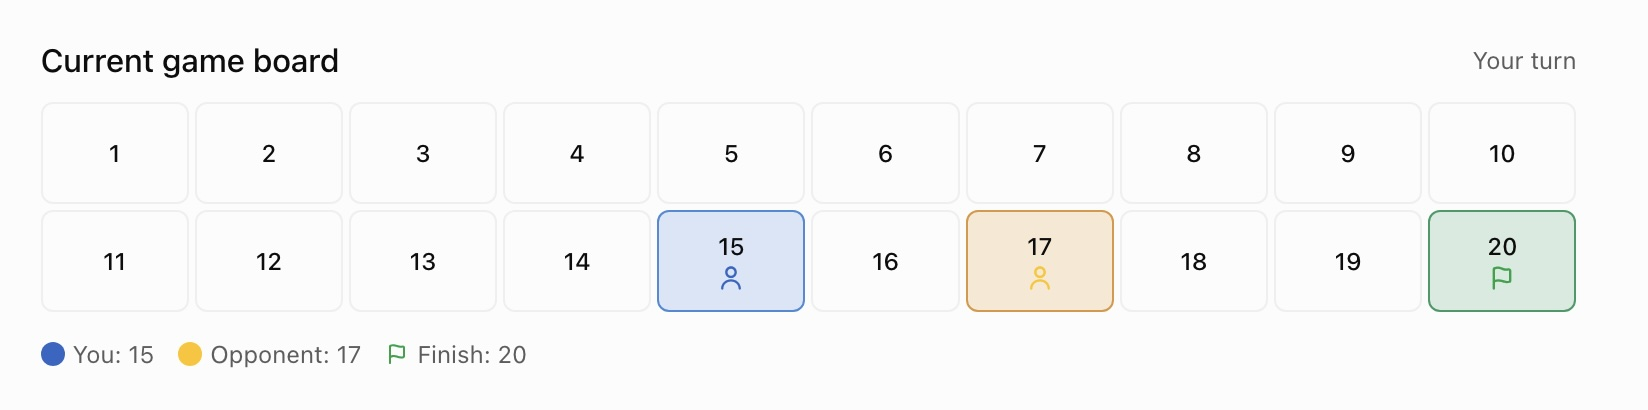

In [13]:
import random
import pandas as pd
import matplotlib.pyplot as plt

# Game settings, these are STATIC variables (capitalized)
GOAL = 20
START_YOU = 15
START_OPPONENT = 17
N = 10000

#defining a single turn in the game
def take_turn(position, strategy):
    roll = random.randint(1, 6)

    if strategy == "risky":
        coin = random.choice(["H", "T"])

        if coin == "H":
            if roll == 1:
              movement = 2
            else:
              movement = int(1.5 * roll)
        else:
            movement = roll - 2
    else:
        movement = roll

    #max ensures you don't "fall off" the board
    return max(1, position + movement)

#method for actual game play
def play_game(your_strategy):
    you = START_YOU
    opponent = START_OPPONENT
    turns = 0

    while True:
        # You move first
        you = take_turn(you, your_strategy)
        turns += 1

        if you >= GOAL:
            return "You", turns

        #randomly select opponent strategy
        opp_strat = random.choice(["risky", "safe"])
        opponent = take_turn(opponent, opp_strat)

        if opponent >= GOAL:
            return "Opponent", turns


# Example: play one game
winner, turns = play_game("risky")

print("Winner:", winner)
print("Your turns:", turns)


Winner: Opponent
Your turns: 1


In [14]:

# Simulate 10,000 individual turns
#creating a two column dataframe, one column for strategy employed, the other for winner
df = pd.DataFrame(columns=["strategy", "outcome"])

for strategy in ["safe", "risky"]:
    for i in range(10000):
        winner, turns = play_game(strategy)
        #storing simulated outcome to last row in df
        df.loc[len(df)] = [strategy, winner]

print(df.head(20))



   strategy   outcome
0      safe       You
1      safe  Opponent
2      safe  Opponent
3      safe       You
4      safe       You
5      safe  Opponent
6      safe  Opponent
7      safe       You
8      safe       You
9      safe  Opponent
10     safe       You
11     safe       You
12     safe  Opponent
13     safe       You
14     safe  Opponent
15     safe       You
16     safe  Opponent
17     safe       You
18     safe       You
19     safe  Opponent


In [15]:
#creating column in df called "win" which stores 1 for your win, 0 for opponent win
df["win"] = (df["outcome"] == "You").astype(int)

summary = df.groupby("strategy")["win"].agg(
    ["mean", "std", "count"]
)

print(summary)


            mean       std  count
strategy                         
risky     0.4429  0.496754  10000
safe      0.5368  0.498669  10000


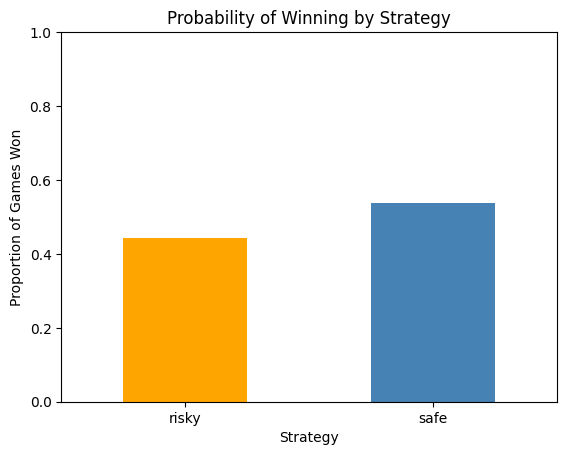

In [16]:

summary["mean"].plot(
    kind="bar",
    color=["orange", "steelblue"]
)

plt.title("Probability of Winning by Strategy")
plt.xlabel("Strategy")
plt.ylabel("Proportion of Games Won")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()
